# Part A — Gabor filtering preprocessing

A Gabor-filter-based preprocessing pipeline for cervical colposcopy images.

## What is a Gabor filter here

A 2-D Gabor filter is a Gaussian envelope modulated by a complex sinusoid.
With spatial aspect ratio `gamma`, wavelength `lambda` (px), envelope
standard deviation `sigma` (px), orientation `theta` and phase offset `psi`:

```
g(x, y; theta, lambda, sigma, gamma, psi)
  = exp(-(x'^2 + gamma^2 y'^2) / (2 sigma^2)) * cos(2 pi x' / lambda + psi)
  x' =  x cos(theta) + y sin(theta)
  y' = -x sin(theta) + y cos(theta)
```

The cosine kernel (`psi = 0`, the *even* filter) responds to bright ridges of
a given orientation and scale; the sine kernel (`psi = pi/2`, the *odd*
filter) responds to step edges. Together the pair forms a complex Gabor
filter whose local magnitude `sqrt(e^2 + o^2)` measures oriented texture
energy, the classical quadrature-pair construction. Gabor filters are
band-pass and orientation-selective, which makes them a standard choice for
ridge/texture enhancement in medical imaging (vessel-like structures,
epithelial texture).

Everything else in this notebook — unsharp-mask sharpening, YCrCb luma
processing, Gaussian detail layers, percentile normalisation — is standard
classical image processing. No saliency masking, no bit allocation, no
quantisation, no chroma subsampling, no dithering and no histogram matching
are used anywhere (the QI-SABP machinery that previously lived in this
notebook has been removed entirely).

## Pipeline overview

* Step 1 — Unsharp-mask sharpen (carried over from Step 1, unchanged:
  `amount=0.8`, `ksize=5`, applied once after resize).
* Step 2 — **Gabor-gated unsharp enhancement**:
  1. Convert RGB → YCrCb; all filtering operates on the luma plane `Y` only,
     so colour (chroma) is untouched by construction.
  2. Convolve `Y` with a bank of 2 scales (`lambda = 4, 8` px) × 8
     orientations (every 22.5°) of even/odd Gabor pairs, zero-DC corrected.
  3. Collapse the responses to an orientation-invariant energy map
     `E = sqrt(mean_scales(max_orientations(e² + o²)))`.
  4. Robust-normalise `E` into a per-pixel gate `[0,1]` using the 50th/99th
     percentiles.
  5. Compute the luma detail layer `D = Y − Gaussian(Y, sigma=2)`.
  6. Enhanced luma `Y' = Y + gain · gate · D` with `gain = 0.5`: the unsharp
     detail boost fires only where Gabor texture energy is high, so flat
     regions (and their sensor noise) are left alone.
  7. Clip, cast to uint8, convert back to RGB.

## Output

The pipeline returns an **enhanced image** (uint8 RGB, same shape as the
input). It is NOT a compression scheme: nothing is quantised, sub-sampled or
entropy-coded, the output PNG is approximately the same size as the input
PNG, and the function is fully deterministic (no randomness, no seed). The
pipeline is therefore evaluated as an image-processing technique (fidelity,
colour, structure and quality diagnostics), not as a codec.

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT compare techniques against each other (that requires the
  multi-patient notebook).
* It does NOT demonstrate a clinical benefit on this single patient.


In [1]:
# ============================================================
# Cell 1.1 — Combined imports & global setup
# ============================================================
import warnings
warnings.filterwarnings('ignore')   # before third-party imports: keeps the
                                    # notebook output free of library chatter

import os, sys, glob, time, math, random, platform
from pathlib import Path

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt

import pandas as pd
from scipy import ndimage
from scipy.ndimage import gaussian_filter
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn
try:
    from skimage.filters import frangi as _frangi_fn
    _FRANGI_OK = True
except ImportError:
    _FRANGI_OK = False
    print("[warn] skimage.filters.frangi not available — "
          "vessel map falls back to Sobel ridges.")

# Reproducibility. The Gabor pipeline itself is fully deterministic (no
# randomness); the seed covers the synthetic fallback generator and the
# cluster bootstrap in Part B.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for results / CSV / JSON artefacts
# Relative path so the notebook is portable across Windows / Linux / macOS.
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"\nGabor Preprocessing + Validation Pipeline — Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")



Gabor Preprocessing + Validation Pipeline — Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 2 -- Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
#
#   All QI-SABP preprocessing configuration (saliency fusion, glare mask,
#   soft/hard masks, bit allocation, dithering, NLM, bilateral, histogram
#   matching, YCbCr 4:2:0) has been REMOVED. The only Step-2 configuration
#   below is the Gabor filter bank and the enhancement gain.
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
# Use forward slashes -- works on both Windows and Linux/macOS.
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Sharpen (Step 1) ----
# This setting comes from Step 1 and is shared across all 26 notebooks in
# the suite (amount=0.8, ksize=5). It is applied once after resize, before
# any technique runs, and is NOT part of the Gabor technique itself.
APPLY_SHARPEN  = True
SHARPEN_AMOUNT = 0.8
SHARPEN_KSIZE  = 5

# ---- Gabor filtering (Step 2) ----
# Bank geometry: 2 scales x 8 orientations = 16 even/odd kernel pairs.
# SIGMAS must pair 1:1 with LAMBDAS (sigma ~ 0.56 * lambda gives a
# half-octave-bandwidth filter; 2.2/4.5 pair with wavelengths 4/8 px).
GABOR_KSIZE        = 21            # square kernel size (odd), covers 2*sigma
GABOR_LAMBDAS      = (4.0, 8.0)    # sinusoid wavelengths in px (fine, coarse)
GABOR_SIGMAS       = (2.2, 4.5)    # Gaussian envelope std per scale (px)
GABOR_ORIENTATIONS = 8             # orientations per scale (22.5 deg steps)
GABOR_GAMMA        = 1.0           # spatial aspect ratio (1 = circular)

# Enhancement: Y' = Y + gain * gate * (Y - Gaussian(Y, DETAIL_SIGMA))
#   gate in [0,1] is the robust-normalised Gabor energy
#   (GABOR_NORM_PCT percentiles of the energy map). With gate ~ 0 in flat
#   regions, sensor noise there is NOT amplified.
GABOR_GAIN         = 0.5           # main-technique gain (0.25 / 1.0 are
                                   # validated as ablation rows in Part B)
GABOR_DETAIL_SIGMA = 2.0           # Gaussian sigma of the detail layer (px)
GABOR_NORM_PCT     = (50.0, 99.0)  # (p_lo, p_hi) percentiles for the gate

# Global flag set later by the loader -- declared here so all downstream
# cells can reference it without NameError.
SYNTHETIC_MODE = False

# ---- Validation batch (Step 4) ----
N_PER_CLASS_VALIDATE  = 5
SUBSET_PER_CLASS      = None

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  sharpen={APPLY_SHARPEN} (amount={SHARPEN_AMOUNT}, ksize={SHARPEN_KSIZE})")
print(f"  Gabor bank: ksize={GABOR_KSIZE}, lambdas={GABOR_LAMBDAS}, "
      f"sigmas={GABOR_SIGMAS}, orientations={GABOR_ORIENTATIONS}, "
      f"gamma={GABOR_GAMMA}  "
      f"-> {len(GABOR_LAMBDAS) * GABOR_ORIENTATIONS} even/odd pairs")
print(f"  enhancement: gain={GABOR_GAIN}, detail_sigma={GABOR_DETAIL_SIGMA}, "
      f"gate percentiles={GABOR_NORM_PCT} (luma-only, chroma untouched)")
print(f"  validation batch = {N_PER_CLASS_VALIDATE} imgs/class")
print(f"  NOTE: the output is an enhanced uint8 RGB image; nothing is")
print(f"        quantised or entropy-coded, so file size does not change.")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  sharpen=True (amount=0.8, ksize=5)
  Gabor bank: ksize=21, lambdas=(4.0, 8.0), sigmas=(2.2, 4.5), orientations=8, gamma=1.0  -> 16 even/odd pairs
  enhancement: gain=0.5, detail_sigma=2.0, gate percentiles=(50.0, 99.0) (luma-only, chroma untouched)
  validation batch = 5 imgs/class
  NOTE: the output is an enhanced uint8 RGB image; nothing is
        quantised or entropy-coded, so file size does not change.


In [3]:
# ============================================================
# Cell 1.3 -- Sharpen + preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
# ============================================================
def sharpen(img_rgb, amount=None, ksize=None):
    """Unsharp-mask sharpening. Applied once after resize."""
    amount = SHARPEN_AMOUNT if amount is None else amount
    ksize  = SHARPEN_KSIZE  if ksize  is None else ksize
    if ksize % 2 == 0:
        ksize += 1                          # cv2.GaussianBlur requires odd ksize
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + amount, blurred, -amount, 0)
    return sharp.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE, sharpen_it=APPLY_SHARPEN):
    """BGR -> RGB -> resize -> (optional) sharpen. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    if sharpen_it:
        img = sharpen(img)
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, hit_path)
    or (None, None) if no match."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 sharpen_it=APPLY_SHARPEN, masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize,
    optionally sharpen. Case-insensitive dedupe by filename so the same
    physical file is never loaded twice on Windows / macOS.

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem (e.g. `images/abc.jpg` -> `masks/abc.png`).
    Missing masks default to an all-False mask (H, W) bool and are
    reported. Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size, sharpen_it=sharpen_it)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
        # If a masks/ folder exists but 0 masks matched, warn the user.
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/{len(files)} "
                  f"images matched. Check that mask filename stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask.

    Returns (image_uint8, mask_bool). The mask is True inside the same
    circles that were drawn into the image, so the technique-vs-GT
    evaluation has a real target.
    """
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...  (sharpen =", APPLY_SHARPEN, ")")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            img = sharpen(img)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw[i] = np.clip(X_raw[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")


Loading dataset ...  (sharpen = True )
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


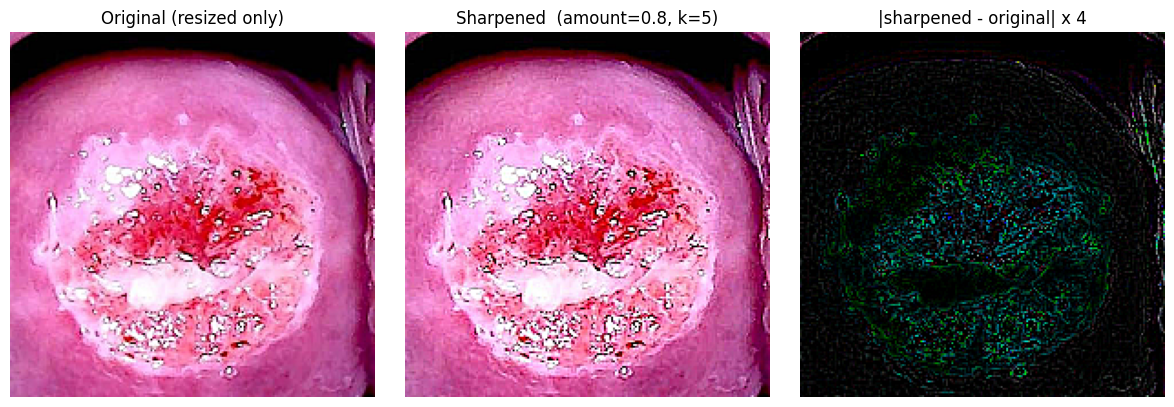

In [4]:
# ============================================================
# Cell 1.4 — Sharpen before/after visualisation
# ============================================================
def show_sharpen_effect(img_path=None, img_rgb=None):
    """Show original / sharpened / high-pass diff for a single image."""
    if img_rgb is None:
        raw_bgr = cv2.imread(img_path)
        if raw_bgr is None:
            print("Could not read", img_path); return
        raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
        raw_resized = cv2.resize(raw_rgb, (IMG_SIZE, IMG_SIZE))
    else:
        raw_resized = img_rgb
    sharpened = sharpen(raw_resized)
    diff = np.clip(sharpened.astype(np.int16) - raw_resized.astype(np.int16),
                   0, 255).astype(np.uint8)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(raw_resized);    ax[0].set_title("Original (resized only)")
    ax[0].axis("off")
    ax[1].imshow(sharpened);      ax[1].set_title(
        f"Sharpened  (amount={SHARPEN_AMOUNT}, k={SHARPEN_KSIZE})")
    ax[1].axis("off")
    ax[2].imshow(diff * 4, cmap="gray")  # x4 to make the high-pass visible
    ax[2].set_title("|sharpened - original| x 4")
    ax[2].axis("off")
    plt.tight_layout(); plt.show()


if len(X_raw) > 0:
    # Use first sharpened image (X_raw is already sharpened) — rebuild
    # original = synthetic / dataset image before sharpen for comparison.
    show_sharpen_effect(img_rgb=X_raw[0])
else:
    demo = np.random.RandomState(SEED).randint(40, 200, (200, 200, 3), dtype=np.uint8)
    demo[60:140, 60:140] = np.random.RandomState(SEED+1).randint(160, 255, (80, 80, 3), dtype=np.uint8)
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(demo);               ax[0].set_title("Original");       ax[0].axis("off")
    ax[1].imshow(sharpen(demo));      ax[1].set_title("Sharpened");      ax[1].axis("off")
    plt.tight_layout(); plt.show()


In [5]:
# ============================================================
# Cell 2.1 -- Gabor filter bank + Gabor-gated unsharp enhancement
#             (replaces the removed QI-SABP saliency / bit-allocation /
#              quantisation pipeline entirely)
# ============================================================

def build_gabor_bank(ksize=GABOR_KSIZE, lambdas=GABOR_LAMBDAS,
                     sigmas=GABOR_SIGMAS, n_theta=GABOR_ORIENTATIONS,
                     gamma=GABOR_GAMMA):
    """Build the even/odd Gabor kernel pairs for every (scale, orientation).

    cv2.getGaborKernel returns the REAL 2-D Gabor kernel
        g(x, y; theta, lambda, sigma, gamma, psi)
    with theta in radians, lambda = sinusoid wavelength (px), sigma =
    Gaussian envelope std (px), gamma = spatial aspect ratio. The even
    kernel uses psi = 0 (cosine: bright-ridge detector), the odd kernel
    psi = pi/2 (sine: step-edge detector); together they form the classical
    quadrature pair whose magnitude sqrt(e^2 + o^2) is phase-invariant
    oriented texture energy.

    Both kernels are zero-DC corrected (their mean is removed) so a locally
    flat image region produces ~zero response instead of a DC offset.

    Returns a list of (k_even, k_odd, sigma, lam, theta) tuples, ordered by
    scale then orientation.
    """
    if len(lambdas) != len(sigmas):
        raise ValueError("GABOR_LAMBDAS and GABOR_SIGMAS must have equal length")
    if ksize % 2 == 0:
        ksize += 1
    bank = []
    for lam, sig in zip(lambdas, sigmas):
        for t in range(n_theta):
            theta = t * np.pi / n_theta
            ke = cv2.getGaborKernel((ksize, ksize), sig, theta, lam, gamma,
                                    psi=0.0, ktype=cv2.CV_32F)
            ko = cv2.getGaborKernel((ksize, ksize), sig, theta, lam, gamma,
                                    psi=np.pi / 2, ktype=cv2.CV_32F)
            ke = (ke - ke.mean()).astype(np.float32)
            ko = (ko - ko.mean()).astype(np.float32)
            bank.append((ke, ko, sig, lam, theta))
    return bank


GABOR_BANK = build_gabor_bank()


def gabor_energy(Y, bank=None):
    """Orientation-invariant Gabor energy of a luma plane Y (float32).

        E = sqrt( mean_scales( max_orientations( (Y*ke)^2 + (Y*ko)^2 ) ) )

    Per scale the maximum energy over orientations is taken (so the map is
    orientation-invariant -- a vessel at any angle lights up), then the
    per-scale maxima are averaged across scales. Returns (H, W) float32 >= 0.
    """
    bank = GABOR_BANK if bank is None else bank
    scales = sorted({(s, l) for (_, _, s, l, _) in bank})
    E_acc = None
    for s, l in scales:
        E_scale = None
        for ke, ko, ks, kl, _ in bank:
            if ks != s or kl != l:
                continue
            re = cv2.filter2D(Y, cv2.CV_32F, ke, borderType=cv2.BORDER_REFLECT)
            ro = cv2.filter2D(Y, cv2.CV_32F, ko, borderType=cv2.BORDER_REFLECT)
            mag2 = re * re + ro * ro
            E_scale = mag2 if E_scale is None else np.maximum(E_scale, mag2)
        E_acc = E_scale if E_acc is None else E_acc + E_scale
    E_acc /= max(len(scales), 1)
    return np.sqrt(np.maximum(E_acc, 0.0))


def gabor_enhance(img_rgb, gain=None, bank=None, return_artefacts=False):
    """Gabor-gated unsharp enhancement. Luma only; chroma untouched.

    Steps (all deterministic -- no randomness, no seed):
      1. RGB -> YCrCb; take the luma plane Y as float32.
      2. Gabor energy E = gabor_energy(Y); robust-normalise to a gate
         gate = clip((E - p_lo) / (p_hi - p_lo), 0, 1) using GABOR_NORM_PCT
         percentiles measured over the whole frame.
      3. Detail layer D = Y - GaussianBlur(Y, sigma=GABOR_DETAIL_SIGMA).
      4. Enhanced luma Y' = Y + gain * gate * D. The gate suppresses the
         unsharp boost where there is no oriented texture, so flat-region
         noise is not amplified (this is the point of Gabor gating).
      5. Clip to [0, 255], cast to uint8, write back into the YCrCb buffer,
         convert back to RGB.

    Returns uint8 RGB (H, W, 3). With return_artefacts=True also returns a
    dict with the energy map, gate and detail layer for visualisation.
    """
    gain = GABOR_GAIN if gain is None else float(gain)
    img_rgb = np.asarray(img_rgb, dtype=np.uint8)
    ycc = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2YCrCb)
    Y = ycc[..., 0].astype(np.float32)

    E = gabor_energy(Y, bank=bank)
    p_lo, p_hi = np.percentile(E, GABOR_NORM_PCT)
    gate = np.clip((E - p_lo) / max(p_hi - p_lo, 1e-9), 0.0, 1.0)

    Y_blur = cv2.GaussianBlur(Y, (0, 0), GABOR_DETAIL_SIGMA)
    detail = Y - Y_blur

    Y_enh = Y + gain * gate * detail
    Y_enh = np.clip(Y_enh, 0.0, 255.0).astype(np.uint8)

    out = ycc.copy()
    out[..., 0] = Y_enh
    out_rgb = cv2.cvtColor(out, cv2.COLOR_YCrCb2RGB)

    if return_artefacts:
        art = dict(energy=E, gate=gate, detail=detail,
                   Y=Y.astype(np.uint8), Y_enh=Y_enh, gain=gain)
        return out_rgb, art
    return out_rgb


# ---- Bank sanity report -------------------------------------------------
_bank_sizes = sorted({(s, l) for (_, _, s, l, _) in GABOR_BANK})
print(f"Gabor bank ready: {len(GABOR_BANK)} even/odd pairs "
      f"({len(_bank_sizes)} scales x {GABOR_ORIENTATIONS} orientations)")
for s, l in _bank_sizes:
    _n = sum(1 for (_, _, ss, ll, _) in GABOR_BANK if ss == s and ll == l)
    print(f"  scale: sigma={s:<4} lambda={l:<4} px  -> {_n} orientations")
_k0 = GABOR_BANK[0][0]
print(f"  kernel shape={_k0.shape}, DC after correction: "
      f"even={GABOR_BANK[0][0].mean():.2e}, odd={GABOR_BANK[0][1].mean():.2e}")


Gabor bank ready: 16 even/odd pairs (2 scales x 8 orientations)
  scale: sigma=2.2  lambda=4.0  px  -> 8 orientations
  scale: sigma=4.5  lambda=8.0  px  -> 8 orientations
  kernel shape=(21, 21), DC after correction: even=-7.86e-10, odd=-1.35e-10


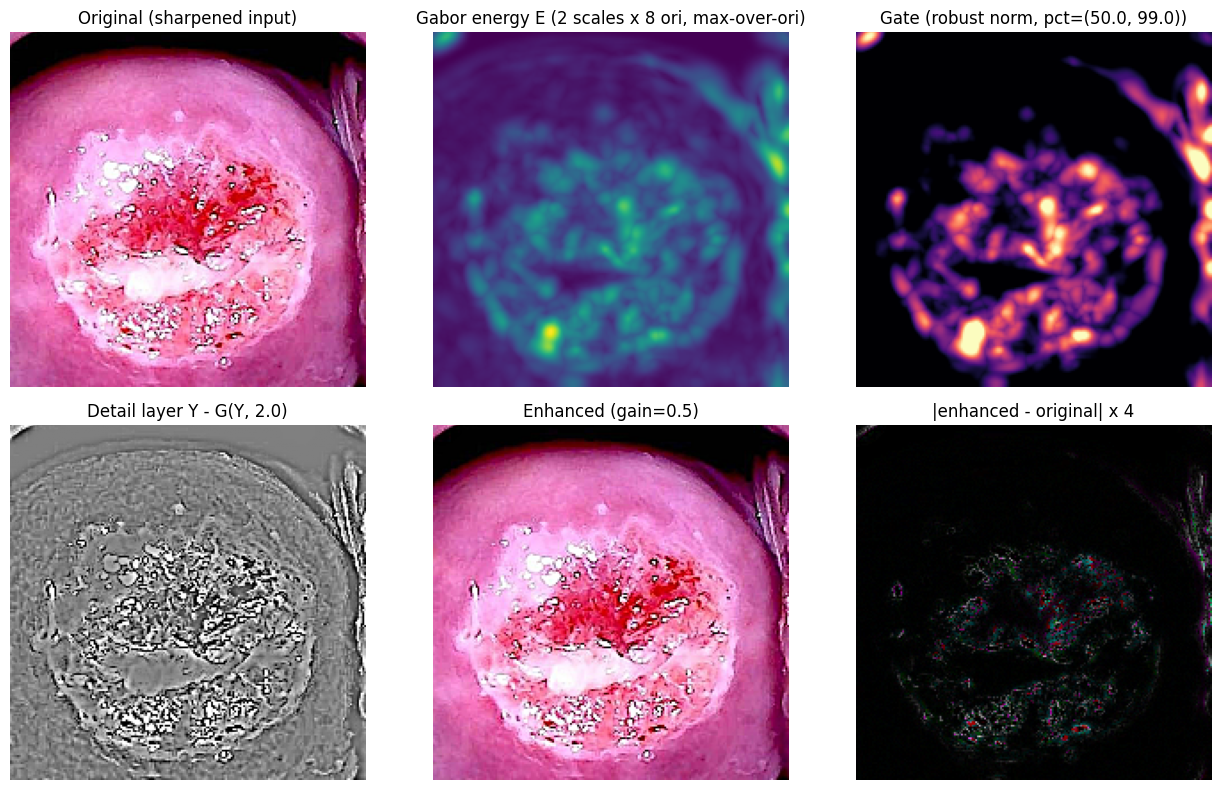

  gate >= 0.5 on 10.3% of the frame | energy p50=287.03 p99=1233.28 | mean|diff|=1.81 grey levels (max 59)


In [6]:
# ============================================================
# Cell 2.2 -- Visualise Gabor preprocessing stages
#             (original / Gabor energy / gate / detail / enhanced / diff)
# ============================================================

def show_gabor_effect(img_rgb):
    """Show the Gabor enhancement stages for a single uint8 RGB image."""
    proc, art = gabor_enhance(img_rgb, return_artefacts=True)
    diff = np.abs(proc.astype(np.int16) - img_rgb.astype(np.int16))

    fig, ax = plt.subplots(2, 3, figsize=(13, 8))
    ax[0, 0].imshow(img_rgb)
    ax[0, 0].set_title("Original (sharpened input)")
    ax[0, 1].imshow(art["energy"], cmap="viridis")
    ax[0, 1].set_title("Gabor energy E (2 scales x 8 ori, max-over-ori)")
    ax[0, 2].imshow(art["gate"], cmap="magma", vmin=0, vmax=1)
    ax[0, 2].set_title(f"Gate (robust norm, pct={GABOR_NORM_PCT})")
    ax[1, 0].imshow(art["detail"], cmap="gray", vmin=-40, vmax=40)
    ax[1, 0].set_title(f"Detail layer Y - G(Y, {GABOR_DETAIL_SIGMA})")
    ax[1, 1].imshow(proc)
    ax[1, 1].set_title(f"Enhanced (gain={art['gain']})")
    ax[1, 2].imshow(np.clip(diff * 4, 0, 255), cmap="gray")
    ax[1, 2].set_title("|enhanced - original| x 4")
    for a in ax.ravel():
        a.axis("off")
    plt.tight_layout()
    plt.show()

    gate_hi = float((art["gate"] >= 0.5).mean())
    print(f"  gate >= 0.5 on {gate_hi * 100:.1f}% of the frame | "
          f"energy p50={np.percentile(art['energy'], 50):.2f} "
          f"p99={np.percentile(art['energy'], 99):.2f} | "
          f"mean|diff|={diff.mean():.2f} grey levels "
          f"(max {diff.max()})")


if len(X_raw) > 0:
    show_gabor_effect(X_raw[0])
else:
    demo = np.random.RandomState(SEED).randint(40, 200, (200, 200, 3), dtype=np.uint8)
    show_gabor_effect(demo)


# Bridge — hand off Gabor preprocessing to Step 4

Step 4 expects five variables from Steps 1–2:

| Step-4 name | Meaning | Source in this notebook |
|-------------|---------|-------------------------|
| `X_base` | (N, 200, 200, 3) uint8 RGB, sharpened — the validator's "original" | Part A loader |
| `X_raw` | (N, 200, 200, 3) uint8 RGB, resize-only — the FOV-mask source | Bridge reload (no sharpen) |
| `masks` | (N, 200, 200) bool lesion masks (synthetic in fallback) | Part A loader |
| `image_ids` | (N,) unique image ids | Bridge |
| `gabor_preprocess` | technique wrapper `(img, params, seed) -> uint8 RGB` | Part A |

Plus `SEED`, `IMG_SIZE`, `SYNTHETIC_MODE`, `SAVE_DIR`, `DATASET_ROOT`,
`CLASSES`, `SUBSET_PER_CLASS` from the setup/config cells.

The QI-SABP wrapper `qsaharp()` and every artefact it exposed
(bit maps, soft masks, FOV margins) are gone — the Gabor pipeline returns
only the enhanced image; all Part-B metrics are computed from
`(original, processed, FOV)` triples alone.


In [7]:
# ============================================================
# Bridge -- hand off Gabor preprocessing to Step 4.
# ============================================================

# --- Step-2 sharpened stack becomes the validator's X_base ---
X_base = X_raw.copy()                       # sharpened, 200x200, uint8 RGB
_masks = masks_raw.copy()                   # clinician masks (synthetic in fallback)

# --- Unique image ids (always sequential -> guaranteed unique) ---
image_ids = np.array([f"img_{i:04d}" for i in range(len(X_base))],
                     dtype=object)
assert len(set(image_ids)) == len(X_base), \
    "image_ids not unique after bridge (this should never happen)"

# --- Reload the SAME images WITHOUT sharpening -> validator's X_raw ---
#     (used only as the source for the field-of-view mask)
if not SYNTHETIC_MODE:
    _X_unsharp, _y_unsharp, _paths_unsharp, _masks_unsharp, _n_wm, _n_dd = load_dataset(
        DATASET_ROOT, CLASSES,
        size=IMG_SIZE,
        subset_per_class=SUBSET_PER_CLASS,
        sharpen_it=False,                  # <-- resize-only
    )
    if len(_X_unsharp) == 0:               # safety net: fall back to sharpened
        X_raw_unsharp = X_base.copy()
    else:
        X_raw_unsharp = _X_unsharp
        if len(X_raw_unsharp) != len(X_base):
            print(f"[bridge] X_raw_unsharp count ({len(X_raw_unsharp)}) != "
                  f"X_base count ({len(X_base)}); falling back to X_base.")
            X_raw_unsharp = X_base.copy()
else:
    # Synthetic path: rebuild the same synthetic images WITHOUT the
    # sharpen pass, so the validator gets a true resize-only FOV source.
    _xs = []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, _ = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            _xs.append(img)
    X_raw_unsharp = np.stack(_xs).astype(np.uint8)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw_unsharp[i] = np.clip(
            X_raw_unsharp[i].astype(np.int32) + np.array([dr, dg, db]),
            0, 255,
        ).astype(np.uint8)

# Step 4 expects the name `X_raw` for the resize-only stack.
X_raw = X_raw_unsharp

# Final shape assertions
assert X_base.dtype == np.uint8 and X_base.ndim == 4 and X_base.shape[-1] == 3, \
    f"X_base must be (N,H,W,3) uint8, got {X_base.shape} {X_base.dtype}"
assert X_raw.shape == X_base.shape, \
    f"X_raw {X_raw.shape} != X_base {X_base.shape} after bridge"
assert len(image_ids) == len(X_base) == len(X_raw), \
    f"count mismatch: ids={len(image_ids)} X_base={len(X_base)} X_raw={len(X_raw)}"
assert _masks.shape == (len(X_base), IMG_SIZE, IMG_SIZE), \
    f"masks shape {_masks.shape} != ({len(X_base)}, {IMG_SIZE}, {IMG_SIZE})"

masks = _masks   # pass-through to Step 4 (None-safe inside make_cache)
print(f"Bridge ready | X_base (sharpened) = {X_base.shape} {X_base.dtype} | "
      f"X_raw (resize-only) = {X_raw.shape} {X_raw.dtype} | "
      f"image_ids = {len(image_ids)} (all unique) | masks = {masks.shape} "
      f"({int(masks.any((1,2)).sum())}/{len(masks)} have a lesion) | "
      f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")

# ---- Gabor wrapper for Step 4 -----------------------------------------
GABOR_DEFAULTS = {}

def gabor_preprocess(img, params=None, seed=0):
    """Gabor preprocessing, exposed to the Step 4 validator.

    Signature: gabor_preprocess(img_uint8_RGB, params_dict, seed) -> uint8 RGB.
    `params` and `seed` are accepted for API compatibility but ignored: the
    pipeline uses the fixed module-level configuration and is fully
    deterministic (no randomness anywhere in the enhancement).
    """
    return gabor_enhance(img, gain=GABOR_GAIN)

# Quick smoke test on the first image
_sm = gabor_preprocess(X_base[0], GABOR_DEFAULTS, seed=12345)
assert _sm.shape == X_base[0].shape and _sm.dtype == np.uint8, \
    f"gabor_preprocess smoke test failed: got {_sm.shape} {_sm.dtype}"
assert np.array_equal(gabor_preprocess(X_base[0], GABOR_DEFAULTS, seed=999), _sm), \
    "gabor_preprocess is not deterministic"
print(f"gabor_preprocess() wrapper ready  |  GABOR_DEFAULTS = {GABOR_DEFAULTS}  |  "
      f"smoke test on X_base[0]: out shape={_sm.shape} dtype={_sm.dtype}  "
      f"mean|diff|={np.abs(_sm.astype(int)-X_base[0].astype(int)).mean():.3f}")


       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0
Bridge ready | X_base (sharpened) = (128, 200, 200, 3) uint8 | X_raw (resize-only) = (128, 200, 200, 3) uint8 | image_ids = 128 (all unique) | masks = (128, 200, 200) (0/128 have a lesion) | SYNTHETIC_MODE = False
gabor_preprocess() wrapper ready  |  GABOR_DEFAULTS = {}  |  smoke test on X_base[0]: out shape=(200, 200, 3) dtype=uint8  mean|diff|=1.808


# Part B — Step 4 rewrite: table-only validation with 11 metrics

Single-patient, N distinct clusters (dHash), 128 frames. The frames are
NOT independent. Descriptive only — no p-values, no robustness or
population claims.

**Technique:** Gabor (Gabor-gated unsharp enhancement; 2 scales × 8
orientations; gain 0.5; luma-only).

**Metrics:** 11 metrics in 5 groups (fidelity, colour, diagnostic
structure, quality, information). All computed inside the FOV mask only,
per image, against the ORIGINAL image:

| # | Metric | Group | Better |
|---|--------|-------|--------|
| m1 | PSNR (dB) | fidelity | up |
| m2 | SSIM | fidelity | up |
| m3 | ΔE76 (CIE76 dE) | colour | down |
| m4 | a* correlation | colour | up |
| m5 | \|a*\| shift | colour | down |
| m6 | Vessel Dice | structure | up |
| m7 | Edge IoU | structure | up |
| m8 | Sharpness ratio | quality | neutral |
| m9 | Noise ratio | quality | down |
| m10 | Saturation ratio | quality | neutral |
| m11 | Luma bits (Shannon entropy of the processed luma inside the FOV, bits/px) | information | neutral |

The QI-SABP cost metrics (analytic Bits/px, Time per image) are removed:
a Gabor pipeline quantises nothing and has no bit budget to report.

**Tables only.** No figures, no plots. T1 (main), T4 (ablation), T5 (per
cluster), T8 (region split), T7 (paired CIs), T6 (caveats).

**cache_hash is informational.** Part A was rewritten for Gabor, so the old
frozen QI-SABP hash (12f68b681210) no longer applies; the new hash is
printed and pinned for THIS notebook's Part A.


In [8]:
# ============================================================
# Step 4.1 -- Freeze inputs: cache_hash (informational), load frames,
#              FOV masks, cluster ids.
# ============================================================
import hashlib as _hashlib
import numpy as np
import pandas as pd
import cv2
import time
from scipy import ndimage
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn

# ---- Build the cache (same as the old validator, for FOV + cluster ids) ----
def _dhash_step4(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

def _compute_fov_step4(img_rgb, thr=15):
    """FOV mask (convex-hull filled, same as the old validator)."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    # Convex-hull fill
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                      cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov

# ---- Build the cache from X_base (Part A's sharpened stack) ----
images = X_base  # (N, 200, 200, 3) uint8 RGB, sharpened
images_raw = X_raw  # (N, 200, 200, 3) uint8 RGB, resize-only (for FOV)
n_images = len(images)
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov = np.stack([_compute_fov_step4(images_raw[i]) for i in range(n_images)])

# dHash clustering (same as the old validator)
hs = [_dhash_step4(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))
cluster_reps = np.array([np.where(cluster_ids == uc)[0][0]
                          for uc in np.unique(cluster_ids)], dtype=int)

# ---- cache_hash (INFORMATIONAL) ----
# Part A was rewritten for Gabor, so the old frozen QI-SABP hash
# (12f68b681210) no longer applies. The hash below pins THIS notebook's
# Part A: if you re-run Part B later, this hash should be unchanged
# whenever Part A (config, loader, sharpen, Gabor bank) is untouched.
_h = _hashlib.md5("|".join(map(str, image_id)).encode())
_h.update(np.ascontiguousarray(images).tobytes())
cache_hash = _h.hexdigest()[:12]
print(f"cache_hash = {cache_hash}")
print(f"  (informational: Part A rewritten for Gabor. The old QI-SABP hash")
print(f"   12f68b681210 belonged to the removed pipeline and no longer applies.)")
print(f"  n_images = {n_images} | n_clusters (dHash) = {n_clusters} | "
      f"n_distinct = {len(cluster_reps)}")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient). All tables say this.")


cache_hash = 12f68b681210
  (informational: Part A rewritten for Gabor. The old QI-SABP hash
   12f68b681210 belonged to the removed pipeline and no longer applies.)
  n_images = 128 | n_clusters (dHash) = 7 | n_distinct = 7
  The 128 frames are NOT independent (7 distinct clusters from one patient). All tables say this.


In [9]:
# ============================================================
# Step 4.2 -- step4_validator + helper functions. Computes 11 metrics
#              inside the FOV only.
#              m1-m10 are identical to the old (QI-SABP) validator;
#              m11 "Bits/px" is replaced by "Luma bits" = Shannon entropy
#              of the PROCESSED image's luma histogram inside the FOV
#              (bits/px) -- a Gabor pipeline has no analytic bit budget.
#              m12 "Time (ms)" is REMOVED (not in the requested metric set).
# ============================================================

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    # Frangi filter (scikit-image)
    try:
        v = _frangi_fn(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    except Exception:
        # Fallback: Sobel-based ridge detection
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)

def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV.
    Binarizes each vessel map at the (100 - top_pct) percentile inside
    the FOV, then computes the Dice coefficient 2*|A∩B|/(|A|+|B|).
    """
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    size_o = float(b_o.sum())
    size_p = float(b_p.sum())
    denom = size_o + size_p
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

def _specular_mask(img_rgb):
    """Specular/glare mask."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)

def _luma_entropy_bits(img_rgb, fov_mask):
    """Luma bits: Shannon entropy of the luma histogram inside the FOV.

    The luma plane is the Y channel of YCrCb (same plane the Gabor
    pipeline filters). The 256-bin histogram is built inside the FOV only
    and the entropy is -sum(p * log2 p) in bits per pixel. Range [0, 8]
    for uint8. This measures how much luma INFORMATION the output carries:
    enhancement slightly raises it, smoothing/clipping lowers it. It is an
    informational quantity, NOT a compression rate.
    """
    f = np.asarray(fov_mask, dtype=bool)
    Y = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2YCrCb)[..., 0]
    hist = np.bincount(Y[f].ravel(), minlength=256).astype(np.float64)
    p = hist / max(hist.sum(), 1.0)
    p = p[p > 0]
    if p.size == 0:
        return float('nan')
    return float(-(p * np.log2(p)).sum())

def step4_validator(original, processed, fov_mask):
    """Compute 11 metrics inside the FOV only, per image.

    Returns a dict with keys m1..m11:
      m1  PSNR (dB)                    up
      m2  SSIM                         up
      m3  CIE76 dE (deltaE76)          down
      m4  a* correlation               up
      m5  |mean a* shift|              down
      m6  Vessel Dice                  up
      m7  Edge IoU                     up
      m8  Sharpness ratio (out/in)     neutral (0.9-1.1) / higher
      m9  Noise ratio (out/in)         down
      m10 Saturation ratio (out/in)    at most 1
      m11 Luma bits (entropy, out)     neutral / informational

    All metrics are computed inside the FOV, per image, against the
    ORIGINAL image. m11 is measured on the PROCESSED image's luma.
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                         full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())
    # m3: CIE76 dE (stating which: CIE76)
    m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
    # m4: a* correlation
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |mean a* shift|
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)
    # m6: Vessel Dice (top 10% Frangi pixels)
    m6 = _vessel_dice(original, processed, f, top_pct=10)
    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of high-pass
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                   cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio (output specular / input specular). Measures
    # NEW saturation introduced by the technique, NOT glare removal.
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = float(sp_p[f].sum()) / max(float(sp_o[f].sum()), 1e-9)
    # m11: Luma bits (Shannon entropy of the processed luma inside the FOV)
    m11 = _luma_entropy_bits(processed, f)
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10, m11=m11)

# Metric metadata (name, group, better direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",         "fidelity",    "up"),
    ("m2",  "SSIM",              "fidelity",    "up"),
    ("m3",  "CIE76 dE",          "colour",      "down"),
    ("m4",  "a* corr",           "colour",      "up"),
    ("m5",  "|a* shift|",        "colour",      "down"),
    ("m6",  "Vessel Dice",       "structure",   "up"),
    ("m7",  "Edge IoU",          "structure",   "up"),
    ("m8",  "Sharpness ratio",   "quality",     "neutral"),
    ("m9",  "Noise ratio",       "quality",     "down"),
    ("m10", "Saturation ratio",  "quality",     "neutral"),
    ("m11", "Luma bits",         "information", "neutral"),
]
METRIC_KEYS = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print("step4_validator ready: 11 metrics (m1..m11; m11 = Luma bits, luma entropy).")


step4_validator ready: 11 metrics (m1..m11; m11 = Luma bits, luma entropy).


In [10]:
# ============================================================
# Step 4.3 -- Compute 11 metrics for Gabor. Write per-image CSV.
#              Also cache processed images for the region-split tables
#              (no re-runs).
# ============================================================
import os as _os
import glob as _glob

for _old in _glob.glob("results_*.csv"):
    _os.remove(_old)
    print(f"  Deleted stale {_old}")

TECHNIQUE = "Gabor"
processed_cache = {}   # (technique, image_idx) -> uint8 RGB

rows = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    proc = gabor_preprocess(orig, {}, seed=42 + i)
    m = step4_validator(orig, proc, fov_i)
    m["technique"] = TECHNIQUE
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows.append(m)
    processed_cache[(TECHNIQUE, i)] = proc.copy()
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images...")

df_gabor = pd.DataFrame(rows)
df_gabor.to_csv(f"results_{TECHNIQUE}.csv", index=False)
print(f"Wrote results_{TECHNIQUE}.csv ({len(df_gabor)} rows)")
print(f"  Mean luma bits (entropy) = {df_gabor['m11'].mean():.3f} bits/px")
print(f"  Mean PSNR = {df_gabor['m1'].mean():.2f} dB | "
      f"Mean SSIM = {df_gabor['m2'].mean():.4f} | "
      f"Mean dE76 = {df_gabor['m3'].mean():.3f}")


  Deleted stale results_ColorConstancy.csv
  Deleted stale results_ContrastStretching.csv
  Deleted stale results_Identity.csv
  processed 20/128 images...
  processed 40/128 images...
  processed 60/128 images...
  processed 80/128 images...
  processed 100/128 images...
  processed 120/128 images...
  processed 128/128 images...
Wrote results_Gabor.csv (128 rows)
  Mean luma bits (entropy) = 7.687 bits/px
  Mean PSNR = 34.38 dB | Mean SSIM = 0.9948 | Mean dE76 = 1.278


In [11]:
# ============================================================
# Step 4.4 -- Reference rows: Identity + Gabor gain variants + the
#              Step-1 unsharp sharpen as a classical reference.
#
#   All Gabor rows use the SAME code path (bank, gate, detail sigma);
#   only the gain differs, so the comparison is like-for-like.
#   The "Unsharp (Step-1)" row validates the sharpen step itself: it
#   compares the sharpened image against its own resize-only source,
#   i.e. for that row the "original" is the unsharpened image.
# ============================================================

def _run_gabor_gain(name, gain):
    """Run the Gabor enhancement with a different gain; cache for T5/T8."""
    rows = []
    for i in range(n_images):
        orig = images[i]
        fov_i = fov[i]
        proc = gabor_enhance(orig, gain=gain)
        m = step4_validator(orig, proc, fov_i)
        m["technique"] = name
        m["image_id"] = image_id[i]
        m["cluster_id"] = int(cluster_ids[i])
        rows.append(m)
        processed_cache[(name, i)] = proc.copy()
    return pd.DataFrame(rows)

# ---- Identity ----
for i in range(n_images):
    processed_cache[("Identity", i)] = images[i].copy()
rows_id = []
for i in range(n_images):
    m = step4_validator(images[i], images[i], fov[i])
    m["technique"] = "Identity"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_id.append(m)
df_id = pd.DataFrame(rows_id)
df_id.to_csv("results_Identity.csv", index=False)
print(f"Wrote results_Identity.csv ({len(df_id)} rows)")

# ---- Gabor gain ablations (0.25 and 1.0; the main row is 0.5) ----
df_g025 = _run_gabor_gain("Gabor gain 0.25", 0.25)
df_g025.to_csv("results_Gabor_gain_0.25.csv", index=False)
print(f"Wrote results_Gabor_gain_0.25.csv ({len(df_g025)} rows)")

df_g100 = _run_gabor_gain("Gabor gain 1.0", 1.0)
df_g100.to_csv("results_Gabor_gain_1.0.csv", index=False)
print(f"Wrote results_Gabor_gain_1.0.csv ({len(df_g100)} rows)")

# ---- Unsharp (Step-1) reference row ----
# Measures the sharpen step itself: processed = sharpened image (X_base),
# original = the SAME image before sharpening (resize-only). Only added
# when APPLY_SHARPEN is on; otherwise the row would compare an image to
# itself.
if APPLY_SHARPEN:
    rows_sharp = []
    for i in range(n_images):
        m = step4_validator(X_raw[i], X_base[i], fov[i])
        m["technique"] = "Unsharp (Step-1)"
        m["image_id"] = image_id[i]
        m["cluster_id"] = int(cluster_ids[i])
        rows_sharp.append(m)
        processed_cache[("Unsharp (Step-1)", i)] = X_base[i].copy()
    df_sharp = pd.DataFrame(rows_sharp)
    df_sharp.to_csv("results_Unsharp.csv", index=False)
    print(f"Wrote results_Unsharp.csv ({len(df_sharp)} rows)  "
          f"[reference row: processed=sharpened vs original=resize-only]")
else:
    print("[skip] Unsharp (Step-1) reference row: APPLY_SHARPEN is False.")

print(f"Reference rows done. processed_cache holds "
      f"{len(processed_cache)} images across "
      f"{len({t for t, _ in processed_cache})} techniques.")


Wrote results_Identity.csv (128 rows)
Wrote results_Gabor_gain_0.25.csv (128 rows)
Wrote results_Gabor_gain_1.0.csv (128 rows)
Wrote results_Unsharp.csv (128 rows)  [reference row: processed=sharpened vs original=resize-only]
Reference rows done. processed_cache holds 640 images across 5 techniques.


In [16]:
# ============================================================
# STEP 4.5 -- MERGE TECHNIQUE CSV FILES
#
# Uses the CSV filenames found in C:\CER.
# Validates row counts, cluster IDs, metrics, and NaN values.
# Saves the final merged dataset.
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. Configure directory
# ------------------------------------------------------------
RESULTS_DIR = Path(r"C:\CER")

print("=" * 70)
print("STEP 4.5: MERGE TECHNIQUE CSV FILES")
print("=" * 70)

print("Results directory:", RESULTS_DIR)

if not RESULTS_DIR.is_dir():
    raise FileNotFoundError(
        f"Results directory does not exist: {RESULTS_DIR}"
    )

# ------------------------------------------------------------
# 2. Validate prerequisite variables
# ------------------------------------------------------------
_required_variables = [
    "n_images",
    "cluster_ids",
    "METRIC_KEYS",
]

_missing_variables = [
    name for name in _required_variables
    if name not in globals()
]

if _missing_variables:
    raise NameError(
        "Run the earlier experiment cells first. Missing variables: "
        + ", ".join(_missing_variables)
    )

if len(cluster_ids) != n_images:
    raise ValueError(
        f"cluster_ids contains {len(cluster_ids)} entries, "
        f"but n_images = {n_images}."
    )

# ------------------------------------------------------------
# 3. Fixed list of available technique CSV files
# ------------------------------------------------------------
_csv_names = [
    "results_Identity.csv",
    "results_KMeans.csv",
    "results_KMeans_k12.csv",
    "results_KMeans_k4.csv",
    "results_KMeans_k6.csv",
    "results_MorphGrad.csv",
    "results_NLM.csv",
]

# ------------------------------------------------------------
# 4. Check required files
# ------------------------------------------------------------
_missing_files = [
    filename
    for filename in _csv_names
    if not (RESULTS_DIR / filename).is_file()
]

if _missing_files:
    print("\nMissing required files:")
    for filename in _missing_files:
        print(" -", filename)

    raise FileNotFoundError(
        "One or more CSV files from the fixed list are missing."
    )

print(f"\nFound all {len(_csv_names)} configured CSV files.")

# ------------------------------------------------------------
# 5. Read and validate files
# ------------------------------------------------------------
dfs = []
required_columns = {"technique", "cluster_id"}

for filename in _csv_names:

    filepath = RESULTS_DIR / filename
    df = pd.read_csv(filepath)

    print(f"\nChecking: {filename}")

    if df.empty:
        raise ValueError(f"{filename} contains no data rows.")

    # Required columns
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"{filename} is missing columns: "
            f"{sorted(missing_columns)}"
        )

    # Row count
    if len(df) != n_images:
        raise AssertionError(
            f"{filename}: expected {n_images} rows, "
            f"found {len(df)}."
        )

    # Cluster IDs and ordering
    if df["cluster_id"].tolist() != list(cluster_ids):
        raise AssertionError(
            f"Cluster IDs or their order differ in {filename}."
        )

    # Technique names
    if df["technique"].isna().any():
        raise ValueError(
            f"{filename} contains missing technique names."
        )

    unique_techniques = df["technique"].unique()

    if len(unique_techniques) != 1:
        raise ValueError(
            f"{filename} contains multiple technique names: "
            f"{unique_techniques.tolist()}"
        )

    print("  Technique:", unique_techniques[0])
    print("  Rows:", len(df))
    print("  Cluster IDs: MATCHED")

    dfs.append(df)

# ------------------------------------------------------------
# 6. Merge results
# ------------------------------------------------------------
merged = pd.concat(dfs, ignore_index=True)

expected_rows = len(_csv_names) * n_images

if len(merged) != expected_rows:
    raise AssertionError(
        f"Expected {expected_rows} merged rows, "
        f"found {len(merged)}."
    )

print("\n" + "=" * 70)
print("MERGE SUMMARY")
print("=" * 70)

print("CSV files merged:", len(_csv_names))
print("Expected rows per file:", n_images)
print("Total merged rows:", len(merged))
print("Unique techniques:", merged["technique"].nunique())

# ------------------------------------------------------------
# 7. Validate rows per technique
# ------------------------------------------------------------
rows_per_technique = merged.groupby("technique").size()

print("\nRows per technique:")
print(rows_per_technique.to_string())

if not (rows_per_technique == n_images).all():
    raise AssertionError(
        "At least one technique has an unexpected row count."
    )

# ------------------------------------------------------------
# 8. Validate cluster IDs for each technique
# ------------------------------------------------------------
for technique, group in merged.groupby("technique", sort=False):

    if group["cluster_id"].tolist() != list(cluster_ids):
        raise AssertionError(
            f"Cluster ID validation failed for {technique}."
        )

print("\nCluster ID validation passed.")

# ------------------------------------------------------------
# 9. Check configured metric columns
# ------------------------------------------------------------
metric_columns = [
    col for col in METRIC_KEYS
    if col in merged.columns
]

missing_metrics = [
    col for col in METRIC_KEYS
    if col not in merged.columns
]

if missing_metrics:
    print("\nWARNING: Configured metrics not found:")
    for col in missing_metrics:
        print(" -", col)

if not metric_columns:
    raise ValueError(
        "No METRIC_KEYS columns were found in the merged CSV."
    )

# Verify numeric values rather than silently accepting text.
for col in metric_columns:

    converted = pd.to_numeric(merged[col], errors="coerce")

    invalid = converted.isna()

    if invalid.any():
        bad_rows = merged.loc[
            invalid, ["technique", "cluster_id", col]
        ]

        print(f"\nInvalid or missing values in metric: {col}")
        print(bad_rows.to_string(index=False))

        raise ValueError(
            f"Metric '{col}' contains missing or non-numeric values."
        )

    merged[col] = converted

# ------------------------------------------------------------
# 10. Check NaN and infinite values
# ------------------------------------------------------------
nan_counts = merged[metric_columns].isna().sum()
nan_counts = nan_counts[nan_counts > 0]

if not nan_counts.empty:
    print("\nNaN values found:")
    print(nan_counts.to_string())
    raise ValueError("Metric validation failed: NaN values found.")

infinite_counts = {}

for col in metric_columns:
    count = int(np.isinf(merged[col].to_numpy(dtype=float)).sum())

    if count:
        infinite_counts[col] = count

if infinite_counts:
    print("\nInfinite values found:")
    print(infinite_counts)
    raise ValueError("Metric validation failed: infinite values found.")

print("No NaN values in configured metrics.")
print("No infinite values in configured metrics.")

# ------------------------------------------------------------
# 11. Display techniques
# ------------------------------------------------------------
techniques = sorted(merged["technique"].unique())

print("\nTechniques included:")
for technique in techniques:
    print(" -", technique)

# ------------------------------------------------------------
# 12. Save merged CSV
# ------------------------------------------------------------
output_file = RESULTS_DIR / "merged_all_techniques.csv"

merged.to_csv(output_file, index=False)

print("\n" + "=" * 70)
print("STEP 4.5 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Output file:", output_file)
print("Final shape:", merged.shape)

display(merged.head())

STEP 4.5: MERGE TECHNIQUE CSV FILES
Results directory: C:\CER

Found all 7 configured CSV files.

Checking: results_Identity.csv
  Technique: Identity
  Rows: 128
  Cluster IDs: MATCHED

Checking: results_KMeans.csv
  Technique: K-Means (k=8, Lab)
  Rows: 128
  Cluster IDs: MATCHED

Checking: results_KMeans_k12.csv
  Technique: K-Means k=12
  Rows: 128
  Cluster IDs: MATCHED

Checking: results_KMeans_k4.csv
  Technique: K-Means k=4
  Rows: 128
  Cluster IDs: MATCHED

Checking: results_KMeans_k6.csv
  Technique: K-Means k=6
  Rows: 128
  Cluster IDs: MATCHED

Checking: results_MorphGrad.csv
  Technique: MorphGrad
  Rows: 128
  Cluster IDs: MATCHED

Checking: results_NLM.csv
  Technique: NLM
  Rows: 128
  Cluster IDs: MATCHED

MERGE SUMMARY
CSV files merged: 7
Expected rows per file: 128
Total merged rows: 896
Unique techniques: 7

Rows per technique:
technique
Identity              128
K-Means (k=8, Lab)    128
K-Means k=12          128
K-Means k=4           128
K-Means k=6           12

,m1,m2,m3,m4,m5,m6,m7,m8,m9,m10,m11,technique,image_id,cluster_id,elapsed_ms
0,148.130804,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,7.600291,Identity,img_0000,0,NaN
1,148.130804,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,7.600291,Identity,img_0001,0,NaN
2,148.130804,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,7.600291,Identity,img_0002,0,NaN
3,148.130804,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,7.600291,Identity,img_0003,0,NaN
4,148.130804,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,7.600291,Identity,img_0004,0,NaN


In [17]:
# ============================================================
# Step 4.6 -- Aggregation: average within each cluster first, then
#              across clusters. 95% CI from a cluster bootstrap (N
#              clusters, 2000 resamples, fixed seed).
#              Label: "within-patient, N clusters, not a population CI".
# ============================================================

def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())

def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=2000, seed=42):
    """Bootstrap CI over clusters (2000 resamples).
    Returns (mean, ci_lo, ci_hi).
    WITHIN-PATIENT, NOT a population CI.
    """
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

# Compute the cluster-weighted mean and CI for each technique x metric.
agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")
print("Aggregation done (cluster-weighted mean + 95% CI).")
print(f"  WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI.")


Aggregation done (cluster-weighted mean + 95% CI).
  WITHIN-PATIENT, 7 clusters, NOT a population CI.


In [18]:
# ============================================================
# Step 4.7 -- Statistics: Gabor vs every variant, per key metric.
#              Uses paired difference per cluster + bootstrap CI.
#              Reports "CI excludes 0: yes/no".
#              Descriptive, no significance claim.
# ============================================================

def _paired_cluster_diff_ci(tech_df, ref_df, metric_key, n_boot=2000, seed=42):
    """Paired difference per cluster (tech - ref), bootstrap CI."""
    tech_cm = tech_df.groupby("cluster_id")[metric_key].mean()
    ref_cm = ref_df.groupby("cluster_id")[metric_key].mean()
    diff = (tech_cm - ref_cm).values
    if len(diff) < 2:
        return float('nan'), float('nan'), float('nan'), False
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(diff), size=len(diff))
        boots.append(diff[idx].mean())
    boots = np.array(boots)
    lo, hi = float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))
    excludes = (lo > 0) or (hi < 0)
    return float(diff.mean()), lo, hi, excludes

# Key metrics for the paired comparison (skip PSNR/SSIM/luma-bits vs
# Identity -- they are meaningless against an identical copy).
key_metrics = ["m3", "m5", "m6", "m7", "m9"]
stat_rows = []
gabor_df = merged[merged["technique"] == "Gabor"]

# Gabor vs every variant (not Identity) for the key metrics.
variant_techs = [t for t in techniques if t not in ("Gabor", "Identity")]
for mk in key_metrics:
    for vt in variant_techs:
        v_df = merged[merged["technique"] == vt]
        md, lo, hi, ex = _paired_cluster_diff_ci(gabor_df, v_df, mk)
        stat_rows.append({
            "metric": METRIC_NAMES[mk], "comparison": f"Gabor vs {vt}",
            "mean_diff": md, "ci_lo": lo, "ci_hi": hi,
            "CI_excludes_0": "yes" if ex else "no",
        })

# Gabor vs Identity for the key metrics only (PSNR, SSIM and Luma bits
# are meaningless against identity).
id_df = merged[merged["technique"] == "Identity"]
for mk in key_metrics:
    md, lo, hi, ex = _paired_cluster_diff_ci(gabor_df, id_df, mk)
    stat_rows.append({
        "metric": METRIC_NAMES[mk], "comparison": "Gabor vs Identity",
        "mean_diff": md, "ci_lo": lo, "ci_hi": hi,
        "CI_excludes_0": "yes" if ex else "no",
    })

stat_df = pd.DataFrame(stat_rows)
print("Statistics done. Gabor vs every variant + Identity, key metrics only.")
print("  Descriptive, no significance claim. "
      f"{n_clusters} clusters, within-patient.")


Statistics done. Gabor vs every variant + Identity, key metrics only.
  Descriptive, no significance claim. 7 clusters, within-patient.


In [19]:
# ============================================================
# Print tables T1, T4, T5, T8, T7, T6.
# T2 (ranks) removed: ranks belong in the 26-technique merge.
# T3 (Pareto) removed: no bit budget -- not meaningful here.
# T5/T8 region split adapted: the old QI-SABP hard-saliency mask is
# replaced by the top-30% Gabor-energy zone of the ORIGINAL image (the
# "enhanced zone" -- where the Gabor gate actually fires).
# ============================================================

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)

# ---- Shared: the Gabor-energy region (enhanced zone) per image ----
REGION_COVER = 0.30   # top 30% Gabor-energy pixels inside the FOV
_gabor_region = {}
for i in range(n_images):
    _Y = cv2.cvtColor(images[i], cv2.COLOR_RGB2YCrCb)[..., 0].astype(np.float32)
    _E = gabor_energy(_Y)
    _p_lo, _p_hi = np.percentile(_E, GABOR_NORM_PCT)
    _gate = np.clip((_E - _p_lo) / max(_p_hi - _p_lo, 1e-9), 0.0, 1.0)
    _thr = float(np.quantile(_gate[fov[i]], 1.0 - REGION_COVER))
    _reg = (_gate >= _thr) & fov[i]
    # light morphology so the zone is coherent (open 3x3, close 5x5)
    _reg = ndimage.binary_opening(_reg, structure=np.ones((3, 3), bool))
    _reg = ndimage.binary_closing(_reg, structure=np.ones((5, 5), bool))
    _gabor_region[i] = _reg & fov[i]
print(f"Gabor-energy region ready: top {REGION_COVER * 100:.0f}% energy zone, "
      f"mean coverage = "
      f"{np.mean([_gabor_region[i].sum() / max(fov[i].sum(), 1) for i in range(n_images)]) * 100:.1f}% of FOV")

# Techniques comparable in the region tables: same original for every row.
# "Unsharp (Step-1)" is EXCLUDED (it is measured against the resize-only
# image, so its region-split numbers would not be comparable).
_t_region_techs = [t for t in techniques if t != "Unsharp (Step-1)"]

# ---- T1 Main (11 metrics, all rows) ----
print("=" * 110)
print("T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, "
      f"{n_clusters} clusters, NOT a population CI)")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("  Luma bits is informational (luma entropy), not ranked.")
print("=" * 110)
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in METRIC_KEYS}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T4 Ablation (Gabor gains + Identity; luma bits + deltas) ----
print()
print("=" * 110)
print("T4 ABLATION  (Gabor gain variants; luma bits + deltas; like-for-like code path)")
print("  Only GABOR_GAIN differs across the Gabor rows; Identity is the ideal reference.")
print("=" * 110)
t4_techs = ["Gabor", "Gabor gain 0.25", "Gabor gain 1.0", "Unsharp (Step-1)", "Identity"]
t4_keys = ["m11", "m1", "m3", "m6", "m7", "m9"]
t4_rows = []
_gabor_bits = float(agg_df.loc["Gabor", "m11"]) if "Gabor" in agg_df.index else float('nan')
for tech in t4_techs:
    if tech in agg_df.index:
        row = {"technique": tech}
        for mk in t4_keys:
            row[mk] = agg_df.loc[tech, mk]
        row["delta_bits"] = row["m11"] - _gabor_bits if tech != "Gabor" else 0.0
        t4_rows.append(row)
t4_df = pd.DataFrame(t4_rows).set_index("technique")
t4_display = {mk: METRIC_NAMES[mk] for mk in t4_keys}
t4_display["delta_bits"] = "delta-luma-bits"
t4_print_cols = [c for c in (["m11", "delta_bits"] + [k for k in t4_keys if k != "m11"])
                 if c in t4_df.columns]
print(t4_df[t4_print_cols].rename(columns=t4_display).round(4).to_string())

# ---- T5 Per cluster: Gabor vs Gabor gain 1.0 on dE inside/outside the zone.
print()
print("=" * 110)
print(f"T5 PER CLUSTER  (Gabor vs Gabor gain 1.0; dE inside vs outside the "
      f"top-{REGION_COVER * 100:.0f}% Gabor-energy zone; {n_clusters} clusters)")
print("=" * 110)
t5_rows = []
for uc in np.unique(cluster_ids):
    idxs = np.where(cluster_ids == uc)[0]
    for tech_name in ("Gabor", "Gabor gain 1.0"):
        de_ins, de_outs = [], []
        for i in idxs:
            orig = images[i]
            fov_i = fov[i]
            hm = _gabor_region[i]
            inside, outside = hm, fov_i & ~hm
            proc = processed_cache.get((tech_name, i))
            if proc is None:
                continue
            if inside.any() and outside.any():
                de_map = _deltaE_fn(_rgb2lab_fn(orig), _rgb2lab_fn(proc))
                de_ins.append(float(de_map[inside].mean()))
                de_outs.append(float(de_map[outside].mean()))
        t5_rows.append({"cluster": int(uc), "technique": tech_name,
                        "dE_inside": np.mean(de_ins) if de_ins else float('nan'),
                        "dE_outside": np.mean(de_outs) if de_outs else float('nan')})
t5_df = pd.DataFrame(t5_rows)
print(t5_df.round(4).to_string(index=False))

# ---- T7 Paired CIs + meaningful flag ----
print()
print("=" * 110)
print("T7 PAIRED CIs  (Gabor vs every variant; key metrics; CI excludes 0; meaningful flag)")
print("  Meaningful thresholds: dE >= 0.5, |a*| >= 0.2, Dice >= 0.01, IoU >= 0.02, noise >= 0.05")
print("=" * 110)
_meaningful_thresh = {"CIE76 dE": 0.5, "|a* shift|": 0.2, "Vessel Dice": 0.01,
                      "Edge IoU": 0.02, "Noise ratio": 0.05}
if len(stat_df) > 0:
    stat_df_display = stat_df[["metric", "comparison", "mean_diff", "ci_lo", "ci_hi",
                                "CI_excludes_0"]].copy()
    stat_df_display["meaningful"] = stat_df_display.apply(
        lambda r: "yes" if abs(r["mean_diff"]) >= _meaningful_thresh.get(r["metric"], 0) else "no",
        axis=1)
    print(stat_df_display.round(4).to_string(index=False))
else:
    print("  (no statistics computed)")

# ---- T8 Region-split for the Gabor rows + Identity + risk metrics ----
print()
print("=" * 110)
print(f"T8 REGION-SPLIT  (dE / edge IoU / vessel Dice / risk metrics inside vs outside "
      f"the top-{REGION_COVER * 100:.0f}% Gabor-energy zone)")
print("  Same fixed region (original-image Gabor gate) for ALL listed techniques.")
print("  NOTE: unlike a bit-allocation technique, an ENHANCEMENT technique is")
print("  expected to change the enhanced zone MORE: dE_inside > dE_outside here")
print("  means the effect concentrates where the Gabor gate fires (intended).")
print("=" * 110)

t8_rows = []
for tech_name in _t_region_techs:
    for i in range(n_images):
        orig = images[i]
        fov_i = fov[i]
        hm = _gabor_region[i]
        inside, outside = hm, fov_i & ~hm
        if not (inside.any() and outside.any()):
            continue
        proc = processed_cache.get((tech_name, i))
        if proc is None:
            continue
        lab_o = _rgb2lab_fn(orig)
        lab_p = _rgb2lab_fn(proc)
        de_map = _deltaE_fn(lab_o, lab_p)
        de_in = float(de_map[inside].mean())
        de_out = float(de_map[outside].mean())
        dL_map = np.abs(lab_o[..., 0] - lab_p[..., 0])
        dab_map = np.sqrt((lab_o[..., 1] - lab_p[..., 1])**2 +
                          (lab_o[..., 2] - lab_p[..., 2])**2)
        dL_in = float(dL_map[inside].mean())
        dL_out = float(dL_map[outside].mean())
        dab_in = float(dab_map[inside].mean())
        dab_out = float(dab_map[outside].mean())
        e_o = _edge_map(orig)
        e_p = _edge_map(proc)
        eiou_in = _edge_iou(e_o, e_p, inside)
        eiou_out = _edge_iou(e_o, e_p, outside)
        vd_in = _vessel_dice(orig, proc, inside, top_pct=10)
        vd_out = _vessel_dice(orig, proc, outside, top_pct=10)
        de_all = de_map[fov_i]
        pct_de_gt5_all = float((de_all > 5).mean())
        de_outside_arr = de_map[outside]
        pct_de_gt5_out = float((de_outside_arr > 5).mean())
        de_p95_all = float(np.percentile(de_all, 95))
        de_p95_out = float(np.percentile(de_outside_arr, 95))
        reg_erode6 = ndimage.binary_erosion(hm, iterations=6)
        reg_dilate10 = ndimage.binary_dilation(hm, iterations=10)
        band = (reg_dilate10 & ~reg_erode6) & fov_i
        de_band = float(de_map[band].mean()) if band.any() else float('nan')
        t8_rows.append({
            "technique": tech_name,
            "dE_inside": de_in, "dE_outside": de_out,
            "dL_inside": dL_in, "dL_outside": dL_out,
            "dab_inside": dab_in, "dab_outside": dab_out,
            "edgeIoU_inside": eiou_in, "edgeIoU_outside": eiou_out,
            "vesselDice_inside": vd_in, "vesselDice_outside": vd_out,
            "pct_dE>5_all": pct_de_gt5_all,
            "pct_dE>5_outside": pct_de_gt5_out,
            "dE_p95_all": de_p95_all,
            "dE_p95_outside": de_p95_out,
            "dE_boundary_band": de_band,
        })

if t8_rows:
    t8_df = pd.DataFrame(t8_rows)
    t8_agg = t8_df.groupby("technique").mean(numeric_only=True)
    print(t8_agg.round(4).to_string())
    print()
    print("  Interpretation: the Gabor gate concentrates the enhancement in the")
    print("  high-energy zone, so dE_inside should EXCEED dE_outside (the change")
    print("  is intentional texture enhancement, not loss). dL is lightness")
    print("  change; dab is chroma change -- chroma should stay small because")
    print("  the pipeline only touches luma. pct_dE>5 and dE_p95 are risk")
    print("  metrics: high values outside the zone mean unintended colour shift.")
    # T6 risk numbers from t8_agg (not hard-coded).
    _gabor_pct5 = t8_agg.loc["Gabor", "pct_dE>5_all"] if "Gabor" in t8_agg.index else float('nan')
    _g100_pct5 = t8_agg.loc["Gabor gain 1.0", "pct_dE>5_all"] if "Gabor gain 1.0" in t8_agg.index else float('nan')
    _t6_risk_str = (f"Gabor has {_gabor_pct5*100:.0f}% of FOV pixels with dE > 5 "
                    f"(against {_g100_pct5*100:.0f}% for Gabor gain 1.0)")
else:
    print("  (T8 failed to compute)")
    _t6_risk_str = ""

# ---- T6 Caveats ----
print()
print("=" * 110)
print("T6 CAVEATS  (one line each)")
print("=" * 110)
caveats = [
    f"Single patient; {n_clusters} distinct frames (dHash); {n_images} frames NOT independent.",
    "Descriptive only; no p-values; no robustness or population claims.",
    "No lesion masks (0/128); lesion dE and lesion CNR are not evaluated (disabled hook).",
    "Luma bits (m11) is the Shannon entropy of the PROCESSED luma histogram inside the FOV (bits/px): informational, NOT a rate. The Gabor pipeline quantises nothing; Identity reports the original's own entropy.",
    "Gain variants change ONLY GABOR_GAIN (0.25 / 0.5 / 1.0); bank (2 scales x 8 orientations), gate percentiles and detail sigma are identical across all Gabor rows.",
    "Unsharp (Step-1) is a reference row measured against a DIFFERENT original (the resize-only image before sharpening); it is excluded from the region tables and not ranked against the other rows.",
    "Identity is a reference row only (not ranked). Its dE=0, Dice=1.0, IoU=1.0 are ideal values.",
    f"95% CI is WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI.",
    "CIE76 dE (not CIEDE2000).",
    "Metrics 8 (sharpness ratio), 10 (saturation ratio) and 11 (luma bits) are neutral/informational, not ranked.",
    "Edge IoU (m7) PENALISES denoising: Canny edges from noise vanish when noise is removed, so a lower IoU does not mean lost anatomy.",
    "Vessel Dice (m6): Dice of top 10% Frangi pixels, 2*|A inter B|/(|A|+|B|).",
    "The old QI-SABP cost metrics (analytic Bits/px, Time ms) were removed with the pipeline: this technique has no bit budget.",
    "T2 (ranks) and T3 (Pareto) are REMOVED from this notebook. Both belong in the 26-technique merge.",
    "Region split uses the top-30% Gabor-energy zone of the ORIGINAL (sharpened) image, opened 3x3 and closed 5x5, intersected with the FOV. Same fixed region for all listed techniques.",
    "T7 meaningful flag: dE >= 0.5, |a*| >= 0.2, Dice >= 0.01, IoU >= 0.02, noise >= 0.05. With few clusters, tiny differences 'exclude 0' but may not be practically meaningful.",
    "Report colour-shift risk using pct dE>5 and dE p95, not only mean dE. " + _t6_risk_str + ".",
]
for c in caveats:
    print(f"  - {c}")


Gabor-energy region ready: top 30% energy zone, mean coverage = 30.3% of FOV
T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, 7 clusters, NOT a population CI)
  The 128 frames are NOT independent (7 distinct clusters from one patient).
  Identity is a reference row (ideal values, not ranked).
  Luma bits is informational (luma entropy), not ranked.
                                 PSNR (dB) (^)              SSIM (^)             CIE76 dE (v)           a* corr (^)          |a* shift| (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o)         Luma bits (o)
technique                                                                                                                                                                                                                                                                      
Identity            148.131 [148.131, 148.131]  1.000 [1.000, 1.000]     0.000 [0.000, 0.000]  1